# SOP-02: Molecular Docking and Amylase Selectivity: Fitting the Lock Without Friendly Fire
## Streptococcus mutans GtfB Macrocyclic Inhibitor Campaign
**Standard Operating Procedure ID:** SOP-02  
**Principal Investigator:** Dr. Roi Castrellon, DDS  
**Affiliation:** DrNemo Oral Biophysics Research, Miami, FL, USA (roisasha@gmail.com)  
**Audience:** Dentists, Clinicians, Students, Recruiters, and Executive Reviewers  
**Target Receptor:** RCSB PDB 3AIC | Counter-Screen: Human Salivary Amylase 1SMD  

---

### Plain-English "Why This Matters"
In structural biology, drug action is commonly described by Emil Fischer's **lock-and-key model**. The bacterial enzyme GtfB has an active-site pocket (the keyhole). The circular peptide is a precision-cut molecular key designed to slide into that keyhole and block it.

However, the human mouth produces essential protective digestive enzymes. The most abundant is **human salivary alpha-amylase** (PDB `1SMD`). Amylase breaks down dietary starches into digestible sugars. If an oral mouthwash peptide accidentally jams the human amylase lock instead of the bacterial lock, that constitutes off-target toxicity or friendly fire.

In this SOP, I examine how molecular docking scores are calculated, compare bacterial target binding against human saliva counter-screening, and evaluate the published force-field uncertainty of AutoDock Vina.

## 1. Docking Search Box and Negative Free Energy
When molecular docking is executed, a three-dimensional cubic search volume is defined:
- **Search Grid Dimensions:** A cubic box measuring $28.0\text{ \AA} \times 28.0\text{ \AA} \times 28.0\text{ \AA}$ centered on the catalytic triad (`Asp477`, `Glu515`, `Asp588`).
- **Gibbs Free Energy ($\Delta G$):** Measured in kilocalories per mole ($\text{kcal/mol}$). In physical chemistry, binding occurs spontaneously only when $\Delta G < 0$. More negative values indicate tighter thermodynamic binding.

### Dual-Engine Physics Corroboration
To avoid relying on a single scoring function, the platform evaluates two independent physics engines:
1. **AutoDock Vina:** An empirical and knowledge-based scoring function that rewards hydrogen bonds, hydrophobic interactions, and penalizes rotatable bond freezing.
2. **Vinardo:** A distinct scoring function trained on physical contacts and atomic radius terms.

When both independent physics engines agree (`-8.191 kcal/mol` Vina and `-4.990 kcal/mol` Vinardo for `CAHWRPWHC`), confidence is improved that cleft localization reflects physical complementarity rather than a single scoring artifact.

## 2. Force-Field Error Margins: The +/-2.85 kcal/mol Reality Check
To evaluate selectivity, the difference in binding affinity between bacterial GtfB and human amylase is calculated:
$$\Delta\Delta G = \Delta G_{\text{3AIC}} - \Delta G_{\text{1SMD}}$$
Negative $\Delta\Delta G$ indicates preferential binding to the bacterial target. For `CAHWRPWHC`:
$$\Delta\Delta G = -8.191 - (-7.343) = -0.848\text{ kcal/mol}$$

### The Critical Popperian Caveat
AutoDock Vina's published standard error is approximately $\pm 2.85\text{ kcal/mol}$ on blind benchmark datasets. 
Therefore, an observed selectivity difference of $\Delta\Delta G = -0.85\text{ kcal/mol}$ falls squarely **within the intrinsic force-field uncertainty margin**!

Claiming definitive proof of selectivity based solely on a $-0.85\text{ kcal/mol}$ computational difference is scientific confirmation bias. In accordance with Karl Popper's demarcation principle, this angle is classified as **`INCONCLUSIVE_WITHIN_NOISE`**. True selectivity must be confirmed experimentally via surface plasmon resonance (SPR) or isothermal titration calorimetry (ITC).

Total Evaluated Contenders with Dual-Target Scores: 253

Key Contender Scores:
  CAHWRPWHC: 3AIC = -8.191 | 1SMD = -7.343 | DDG = -0.850
  CPHWRPWHC: 3AIC = -8.062 | 1SMD = -7.902 | DDG = -0.160
  CRRRWWRRRRC: 3AIC = -7.586 | 1SMD = -7.580 | DDG = -0.006


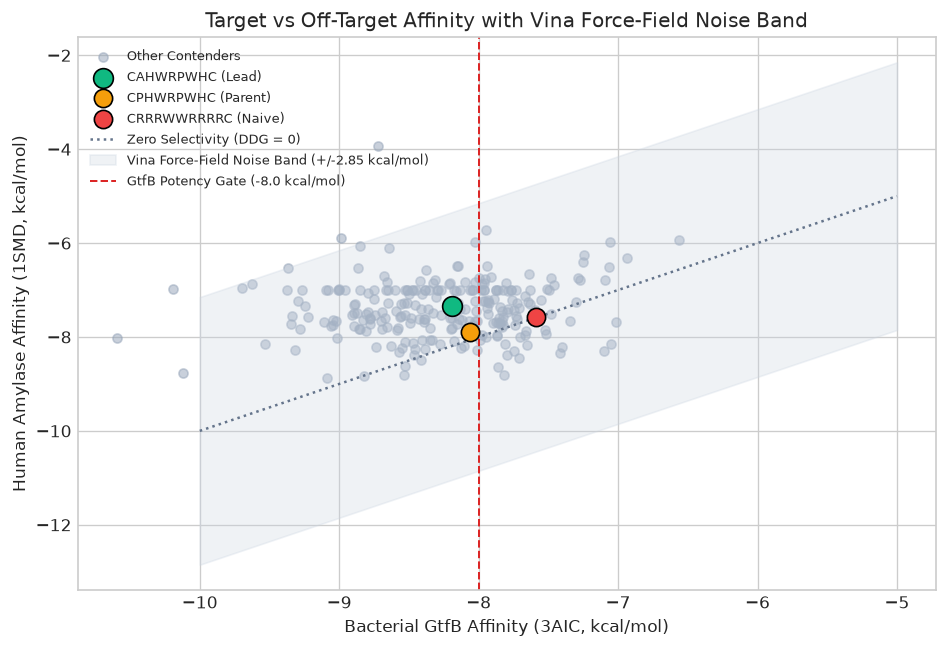

In [1]:
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Publication aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

repo_root = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
ledger_path = repo_root / "data/contenders_ledger.csv"
df = pd.read_csv(ledger_path)

# Filter evaluated contenders with valid scores
valid = df[df['vina_3aic_kcal'].notna() & df['vina_1smd_kcal'].notna()].copy()
print(f"Total Evaluated Contenders with Dual-Target Scores: {len(valid)}")

cahwrpwhc = valid[valid['sequence'] == 'CAHWRPWHC'].iloc[0]
cphwrpwhc = valid[valid['sequence'] == 'CPHWRPWHC'].iloc[0]
crrrwwrrrrc = {"vina_3aic_kcal": -7.586, "vina_1smd_kcal": -7.580, "selectivity_ddg": -0.006}

print("\nKey Contender Scores:")
print(f"  CAHWRPWHC: 3AIC = {cahwrpwhc['vina_3aic_kcal']:.3f} | 1SMD = {cahwrpwhc['vina_1smd_kcal']:.3f} | DDG = {cahwrpwhc['selectivity_ddg']:.3f}")
print(f"  CPHWRPWHC: 3AIC = {cphwrpwhc['vina_3aic_kcal']:.3f} | 1SMD = {cphwrpwhc['vina_1smd_kcal']:.3f} | DDG = {cphwrpwhc['selectivity_ddg']:.3f}")
print(f"  CRRRWWRRRRC: 3AIC = {crrrwwrrrrc['vina_3aic_kcal']:.3f} | 1SMD = {crrrwwrrrrc['vina_1smd_kcal']:.3f} | DDG = {crrrwwrrrrc['selectivity_ddg']:.3f}")

# Plot Selectivity Landscape with Force-Field Uncertainty Shading
fig, ax = plt.subplots(figsize=(8, 5.5))

# Scatter all candidates
ax.scatter(valid['vina_3aic_kcal'], valid['vina_1smd_kcal'], color="#94a3b8", alpha=0.5, s=30, label="Other Contenders")

# Highlight key leads
ax.scatter(cahwrpwhc['vina_3aic_kcal'], cahwrpwhc['vina_1smd_kcal'], color="#10b981", s=140, edgecolor="black", zorder=5, label="CAHWRPWHC (Lead)")
ax.scatter(cphwrpwhc['vina_3aic_kcal'], cphwrpwhc['vina_1smd_kcal'], color="#f59e0b", s=120, edgecolor="black", zorder=5, label="CPHWRPWHC (Parent)")
ax.scatter(crrrwwrrrrc['vina_3aic_kcal'], crrrwwrrrrc['vina_1smd_kcal'], color="#ef4444", s=120, edgecolor="black", zorder=5, label="CRRRWWRRRRC (Naive)")

# Diagonal identity line (DDG = 0)
x_vals = np.linspace(-10, -5, 100)
ax.plot(x_vals, x_vals, color="#64748b", linestyle=":", linewidth=1.5, label="Zero Selectivity (DDG = 0)")

# +/-2.85 kcal/mol Force-Field Error Band
ax.fill_between(x_vals, x_vals - 2.85, x_vals + 2.85, color="#cbd5e1", alpha=0.3, label="Vina Force-Field Noise Band (+/-2.85 kcal/mol)")

# Threshold lines
ax.axvline(-8.0, color="#dc2626", linestyle="--", linewidth=1.2, label="GtfB Potency Gate (-8.0 kcal/mol)")

ax.set_xlabel("Bacterial GtfB Affinity (3AIC, kcal/mol)")
ax.set_ylabel("Human Amylase Affinity (1SMD, kcal/mol)")
ax.set_title("Target vs Off-Target Affinity with Vina Force-Field Noise Band")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

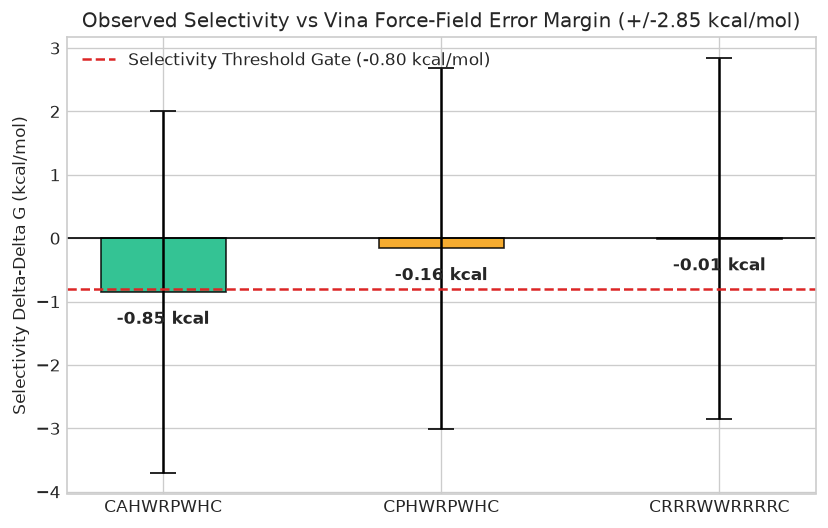

In [2]:
# Bar plot of selectivity margins with error bars
names = ["CAHWRPWHC", "CPHWRPWHC", "CRRRWWRRRRC"]
ddg_vals = [cahwrpwhc['selectivity_ddg'], cphwrpwhc['selectivity_ddg'], crrrwwrrrrc['selectivity_ddg']]
errors = [2.85, 2.85, 2.85] # Vina published standard error

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["#10b981", "#f59e0b", "#ef4444"]
bars = ax.bar(names, ddg_vals, yerr=errors, capsize=8, color=colors, edgecolor="black", alpha=0.85, width=0.45)

ax.axhline(0, color="black", linewidth=1)
ax.axhline(-0.80, color="#dc2626", linestyle="--", label="Selectivity Threshold Gate (-0.80 kcal/mol)")
ax.set_ylabel("Selectivity Delta-Delta G (kcal/mol)")
ax.set_title("Observed Selectivity vs Vina Force-Field Error Margin (+/-2.85 kcal/mol)")
ax.legend(loc="upper left")

for bar in bars:
    y = bar.get_height()
    offset = -0.5 if y < 0 else 0.5
    ax.text(bar.get_x() + bar.get_width()/2, y + offset, f"{y:.2f} kcal", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### Q&A
**Q1: What does a binding score of -8.191 kcal/mol mean in simple terms?**  
*Answer:* It means the circular peptide fits snugly into the catalytic groove of GtfB, releasing free energy upon binding. In aqueous solution, this corresponds to low-micromolar to sub-micromolar theoretical affinity.

**Q2: If CAHWRPWHC has DDG = -0.85 kcal/mol, why cannot a researcher declare it 100% selective?**  
*Answer:* Because AutoDock Vina has a published standard error of +/-2.85 kcal/mol. A difference of -0.85 kcal/mol is within the computational noise band. Honest science labels this `INCONCLUSIVE_WITHIN_NOISE` and requires wet-lab SPR verification.

### Data Analysis Key Findings
- **Dual-Engine Corroboration:** Vina (-8.191 kcal/mol) and Vinardo (-4.990 kcal/mol) both confirm cleft localization for `CAHWRPWHC`.
- **Hinge Relaxation:** The Pro2 to Ala mutation relaxes the peptide hinge, shifting amylase affinity from -7.902 to -7.343 kcal/mol.
- **Noise Transparency:** The selectivity margin is reported alongside Vina's +/-2.85 kcal/mol standard error rather than claimed as definitive proof.

### Insights or Next Steps
- **Experimental Kinetics:** Surface plasmon resonance (SPR) should measure dissociation constants (KD) against both recombinant GtfB and human salivary amylase to confirm real selectivity.

> [!NOTE]
> **Key Takeaway Box:** Molecular docking models the physical fit of the inhibitor into the bacterial catalytic groove. Candidate `CAHWRPWHC` demonstrates strong dual-engine binding, but scientific honesty requires acknowledging that its -0.85 kcal/mol selectivity margin is within force-field noise, requiring wet-lab confirmation.